In [1]:
import math
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from optical_communication_system.components import *
from optical_communication_system.components.utils import normalize_signal
from optical_communication_system.plot import *

2024-08-26 22:43:16.267029: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-08-26 22:43:16.306885: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-08-26 22:43:16.306912: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-08-26 22:43:16.308090: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-08-26 22:43:16.314289: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-08-26 22:43:16.314672: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [7]:
data_rate = 1e9
sampling_rate = data_rate * 10

lpf = ElectricalLowPassFilter(cutoff_frequency=1 * data_rate)

qam4_constellation = IQConstellation(
    bits_per_symbol=2,
    mapping=[
        [-1.0, -1.0], [-1.0, 1.0],
        [ 1.0, -1.0], [ 1.0, 1.0]
    ],
    adjust_for_mzm=True,
    name="qam4_constellation"
)

qam16_constellation = IQConstellation(
    bits_per_symbol=4,
    mapping=[
        [-1.0, -1.0], [-1.0, -0.5], [-1.0, 0.5], [-1.0, 1.0],
        [-0.5, -1.0], [-0.5, -0.5], [-0.5, 0.5], [-0.5, 1.0],
        [ 0.5, -1.0], [ 0.5, -0.5], [ 0.5, 0.5], [ 0.5, 1.0],
        [ 1.0, -1.0], [ 1.0, -0.5], [ 1.0, 0.5], [ 1.0, 1.0]
    ],
    adjust_for_mzm=True,
    name="qam16_constellation"
)

encoder = System(components=[
    IQEncoder(
        sampling_rate=sampling_rate,
        data_rate=data_rate,
        constellation=qam16_constellation
    ),
    MapComponent(component=lpf),
], name="qam_encoder")

qam_transmitter = System(components=[
    IQModulator(
        carrier_source=Laser(power=2e-3, linewidth=10e9, frequency_count=128),
        name="iq_modulator"
    ),
    OpticalAWGN(level=-30.0, name="optical_awgn")
], name="qam_transmitter")

channel = OpticalFiber(attenuation=0.22, length=40.0, chromatic_dispersion=17.0, name="channel")
qam_receiver = IQReceiver(
    photodiode=System(components=[Photodiode(), lpf]),
    name="qam_receiver"
)
qam_decoder = IQDecoder(
    data_rate=data_rate,
    constellation=qam16_constellation,
    name="qam_decoder"
)

rng = tf.random.Generator.from_non_deterministic_state(alg="philox")

system = System(components=[
    encoder,
    qam_transmitter,
    channel,
    qam_receiver,
    qam_decoder
])

ber_tester = BERTester([system])

In [17]:
input_signal = tf.constant([1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1], dtype=tf.int32)
#input_signal = rng.uniform((512,), 0, 2, dtype=tf.int32)

system.capture(input_signal)

<tf.Tensor: shape=(16,), dtype=int32, numpy=array([1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1], dtype=int32)>

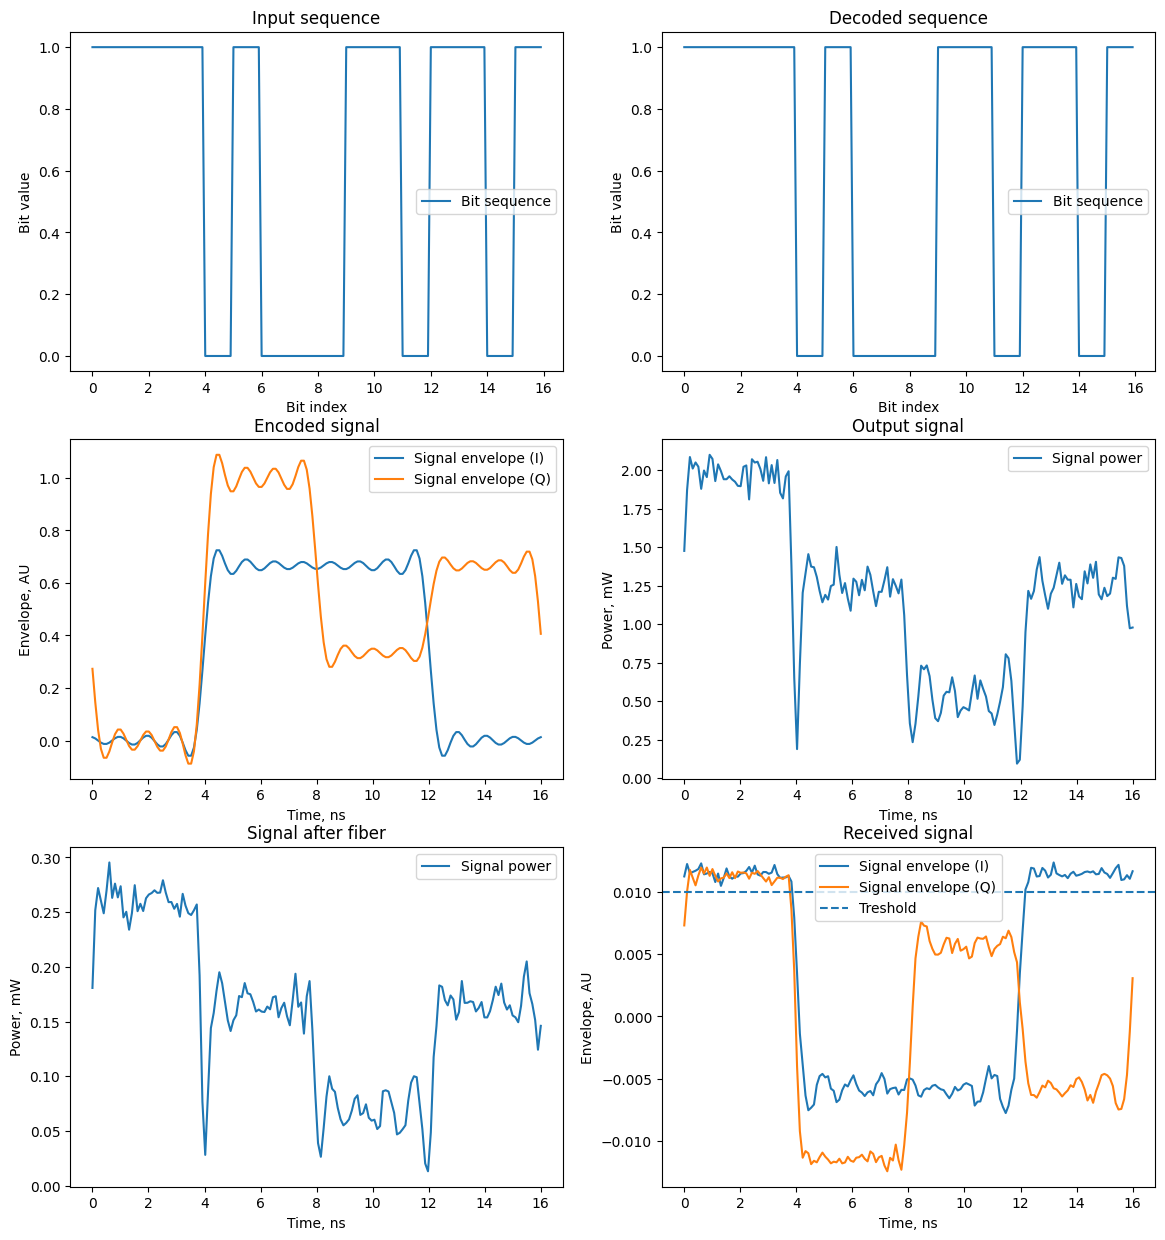

In [10]:
fig, ((input_ax, decoded_ax), (encoded_ax, output_ax), (fiber_ax, received_ax)) = plt.subplots(3, 2)  # type: ignore
fig.set_size_inches(14, 15)

axes = [
    (input_ax, "Input sequence"),
    (encoded_ax, "Encoded signal"),
    (output_ax, "Output signal"),
    (fiber_ax, "Signal after fiber"),
    (received_ax, "Received signal"),
    (decoded_ax, "Decoded sequence")
]

plot_bitseq(input_signal, input_ax)
plot_envelope(system.find_child("qam_encoder").output, encoded_ax)
plot_power(system.find_child("qam_transmitter").output, output_ax)
plot_power(system.find_child("channel").output, fiber_ax)

plot_envelope(system.find_child("qam_receiver").output, received_ax)
received_ax.axhline(qam_decoder.threshold * 1000, linestyle="--", label="Treshold")

plot_bitseq(system.output, decoded_ax)

for ax, title in axes:
    ax.set_title(title)
    ax.legend()

In [12]:
%time ber_tester(128, 100)

CPU times: user 8.37 s, sys: 904 ms, total: 9.27 s
Wall time: 7.44 s


<tf.Tensor: shape=(1,), dtype=float32, numpy=array([0.], dtype=float32)>

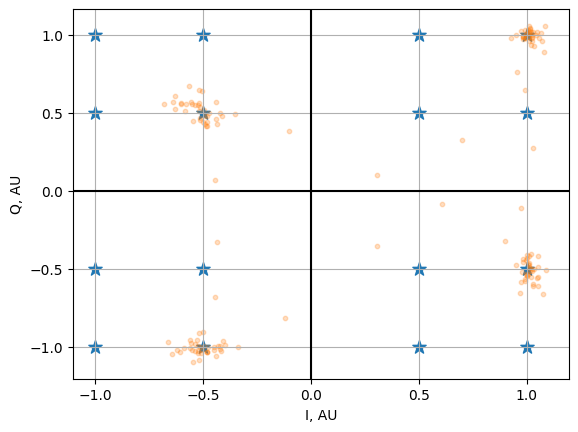

In [13]:
plt.axhline(0.0, color="black")
plt.axvline(0.0, color="black")
plt.grid()
plot_iq_constellation(qam16_constellation, s=100, marker="*")
plot_iq_constellation(system.find_child("qam_receiver").output, s=10, iq_units=(88.0, "AU"), alpha=0.25)

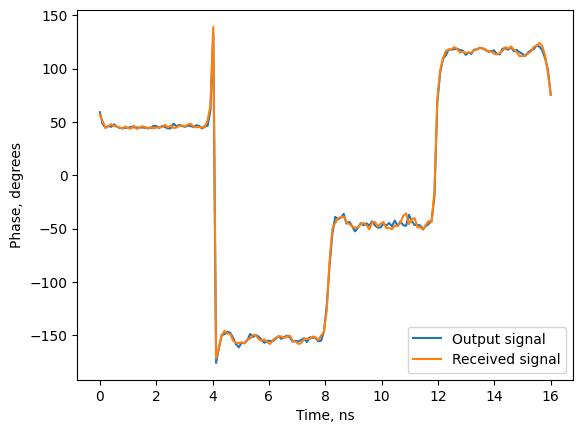

In [15]:
plot_phase(system.find_child("qam_transmitter").output, label="Output signal")
plot_phase(system.find_child("qam_receiver").output, label="Received signal")
plt.legend()

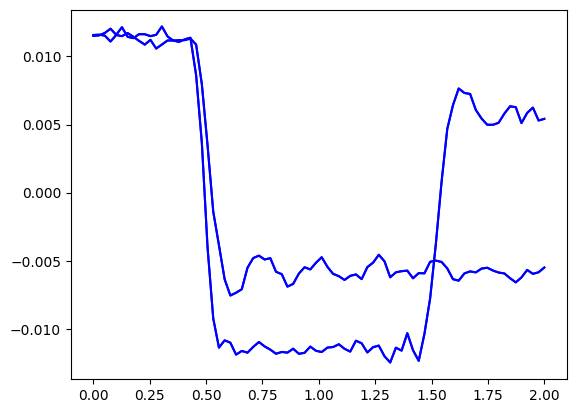

In [16]:
for signal in system.find_child("qam_receiver").output:
    plot_eye_diagram(signal, color="blue", alpha=1)
    plot_eye_diagram(signal, color="blue", alpha=1)

In [20]:
coherent_receiver = System(components=[
    MapComponents(components=[
        System(components=[
            encoder,
            qam_transmitter,
            channel,
            OpticalCoupler1x2()
        ]),
        System(components=[
            Laser(power=2e-3, linewidth=1e9, frequency_count=128),
            OpticalCoupler1x2(),
            MapComponents(components=[
                OpticalPhaseShifter(phase_shift=math.pi / 2),
                Identity()
            ])
        ])
    ]),
    Reindex(indices=[[(1, 1), (0, 0)], [(0, 1), (1, 0)]]),
    MapComponent(
        component=System(components=[
            OpticalCoupler2x2(flip=True),
            MapComponent(component=Photodiode()),
            ElectricalSubtractor()
        ])
    ),
    qam_decoder
])
out = coherent_receiver((input_signal, encoded_signal[0].timing))

In [21]:
out == input_signal

<tf.Tensor: shape=(16,), dtype=bool, numpy=
array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True])>

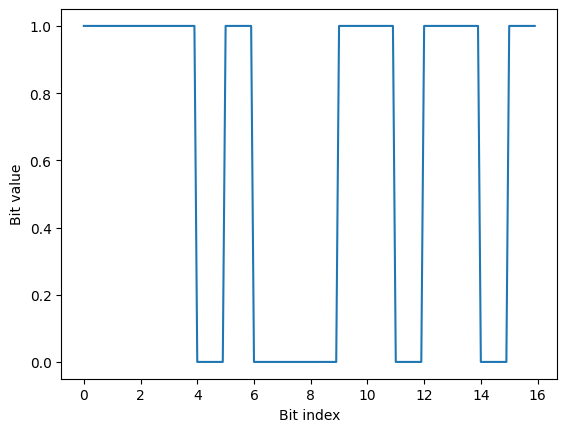

In [22]:
plot_bitseq(out)

In [23]:
%time system(input_signal)

CPU times: user 4.71 ms, sys: 7.58 ms, total: 12.3 ms
Wall time: 7.3 ms


<tf.Tensor: shape=(16,), dtype=int32, numpy=array([1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1], dtype=int32)>

In [24]:
system.capture(input_signal)

<tf.Tensor: shape=(16,), dtype=int32, numpy=array([1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1], dtype=int32)>

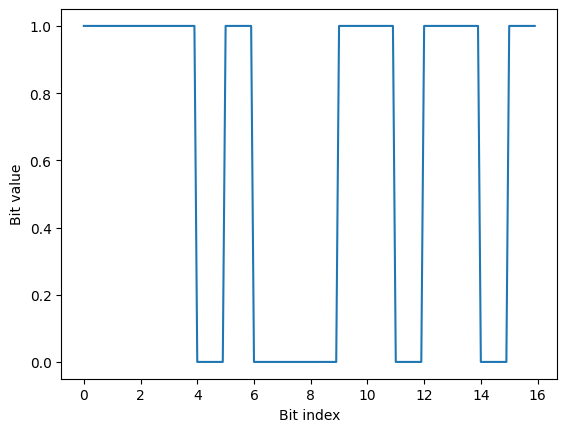

In [27]:
plot_bitseq(system.components[-1].output)